> **Web-runner version** of the Colab participant notebook. `data_dir` and `out_dir` are parameters set by the server; the last cell exports map layers for the viewer. Everything else is the original teaching material.

# Module 3 – Exploratory Spatial Data Analysis and Visualisation
**Participant notebook (R in Google Colab)**

This notebook contains every code cell of the training manual, in the same order and with the same step numbers, so you can run it alongside the manual. Run the cells from top to bottom; each topic depends on objects created earlier.

Before starting: **Runtime → Change runtime type → Language: R**. Then run the setup cells. When a session resets, run the setup cells again and continue where you were.

Text cells give the step; the manual has the explanations, the expected outputs and the figures, so compare your output with the manual after each cell.

# Introduction to Module 3

### Module 3 visual roadmap

*This overview introduces the main ideas you will meet in Module 3 before you begin the step-by-step analysis.*

<div style="text-align:center; margin: 14px 0 26px 0;">
  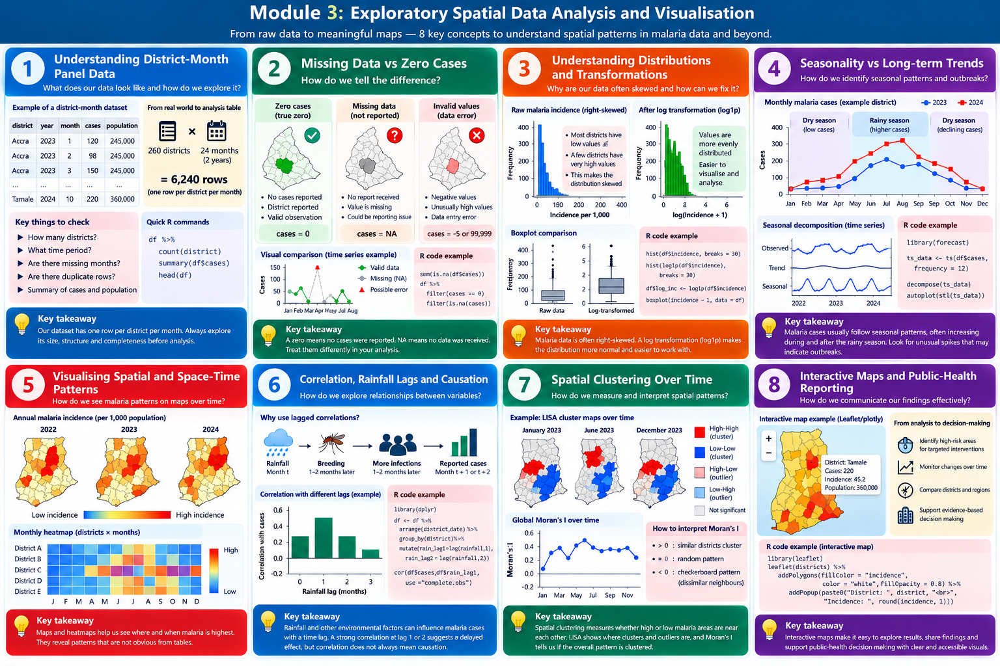
</div>


## Setting up: Google Colab and R

The routine is the one from Modules 1 and 2: open an R notebook, run the download cell, run the install cell, work, and download anything you want to keep before the session ends. Only the file names change.

In [ ]:
# Parameters: the web app (papermill) overrides these for every run.
data_dir    <- "/data/module3_data"
out_dir     <- "/srv/jobs/outputs"

In [ ]:
project_dir <- file.path(out_dir, "project")      # Module 2 builds its project folder here
dir.create(out_dir, showWarnings = FALSE, recursive = TRUE)
# a data zip with one extra top-level folder: step into it
.sub <- list.dirs(data_dir, recursive = FALSE); .fil <- list.files(data_dir)
if (length(.sub) == 1 && length(.fil) == 0) data_dir <- .sub
cat("Data directory:", data_dir, "\n")
list.files(data_dir, recursive = TRUE)

Packages. spdep is the Module 1 package for neighbours and Moran's I; corrplot draws a correlation matrix; leaflet builds interactive maps; htmlwidgets saves them as HTML files; patchwork and scales help with figures.

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
suppressPackageStartupMessages({
  library(tidyverse); library(sf); library(spdep); library(scales); library(patchwork); library(corrplot)
})
options(width = 95)
dir.create(out_dir, showWarnings = FALSE)

### Loading the panel

Read the three files, check the size of the panel and read the dictionary once. In this module the dictionary is the reference for every column name; keep it open.

In [ ]:
panel     <- read_rds(file.path(data_dir, "panel.rds"))
districts <- st_read(file.path(data_dir, "ghana_districts.gpkg"), quiet = TRUE)
dictionary <- read_csv(file.path(data_dir, "data_dictionary.csv"), show_col_types = FALSE)
dim(panel)
print(dictionary, n = 30)

The panel carries only adm2_code. Attach the district name, region and ecological zone once, from the boundary file, so that every table and figure can be labelled. The geometry is dropped so the panel stays a plain table; the map is joined back only when a map is drawn.

In [ ]:
# attach names, region and eco-zone once; keep the panel tidy (one row per district-month)
panel <- panel |> left_join(districts |> st_drop_geometry(), by = "adm2_code")
panel |> select(adm2_code, adm2_name, region, eco_zone, month, confirmed, incidence_1000, rain_mm) |> head(4)

# Topic 1 – Exploring the Panel Before Modelling

### Visual explainer: Understanding district-month panel data

*Use this before Topic 1 to understand what one row in the panel means and what basic checks matter first.*

<div style="text-align:center; margin: 14px 0 26px 0;">
  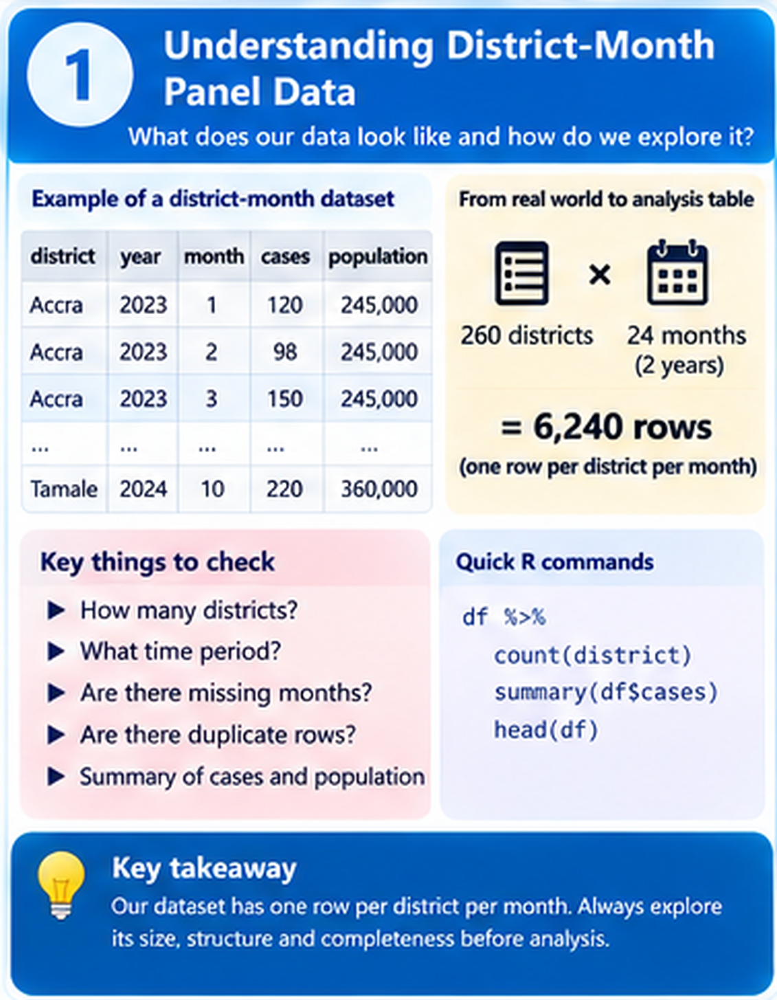
</div>


## 1.4 Step by step in R with Ama's data

Step 1. How the panel divides into training and test months and wet and dry seasons, and the first summary of the outcome over reported district-months.

In [ ]:
panel |> count(split, season)
panel |> filter(reported) |> summarise(n = n(), mean = mean(incidence_1000), median = median(incidence_1000),
                                       p90 = quantile(incidence_1000, 0.9), max = max(incidence_1000))

4,680 training rows and 1,560 test rows, as set in Module 2. Among the 5,556 reported district-months the mean is 11.3 and the median 9.8 per 1,000; the maximum of 494 is Bongo's August 2024 entry error, still present because this summary did not exclude flagged rows. Step 2 does.

Step 2. Count the usable rows, and show where the gaps are by region and by month.

### Visual explainer: Missing data versus zero cases

*This helps distinguish true zero cases from missing reports and shows why that matters in ESDA.*

<div style="text-align:center; margin: 14px 0 26px 0;">
  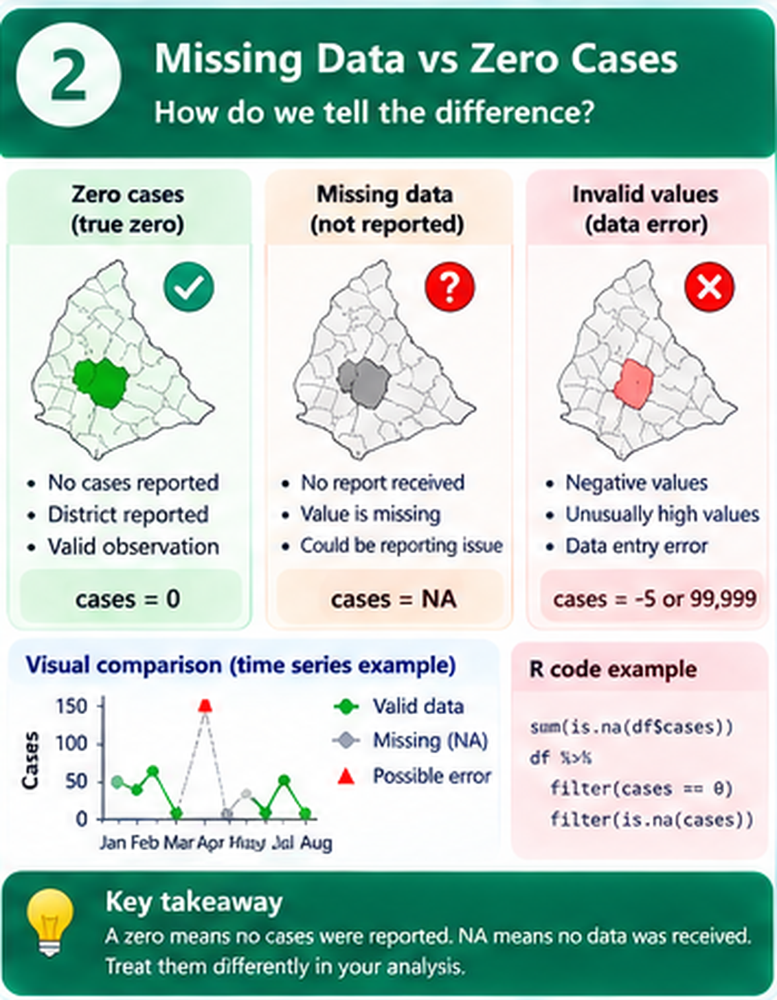
</div>


In [ ]:
# usable rows for modelling: reported, no outlier flag
usable <- panel |> mutate(usable = reported & !flag_outlier)
usable |> count(usable)
usable |> group_by(region) |> summarise(districts = n_distinct(adm2_code), usable_share = round(mean(usable), 2)) |>
  arrange(usable_share) |> print(n = 16)
usable |> group_by(month) |> summarise(missing = sum(!usable)) |> filter(missing == max(missing) | missing == min(missing))

5,549 usable district-months and 691 not usable. Every region keeps at least 84 percent of its months (Central is lowest, Upper East and Upper West highest at 92 percent). The month with the most gaps is July 2024 with 36 districts missing, in the middle of the peak season, which is worth knowing before a model is judged on the 2024 test months.

Step 3. The distribution: quantiles, the by-zone summary, and a skewness number before and after taking logs.

In [ ]:
panel |> filter(reported) |> pull(incidence_1000) |> quantile(c(0, .25, .5, .75, .95, 1)) |> round(1)
panel |> filter(reported) |> group_by(eco_zone) |> summarise(districts = n_distinct(adm2_code), median = median(incidence_1000), p90 = quantile(incidence_1000, .9)) |> arrange(-median)
skew <- function(x) mean(((x - mean(x)) / sd(x))^3)
panel |> filter(reported) |> summarise(skew_raw = skew(incidence_1000), skew_log = skew(log1p(incidence_1000)))

Half of all reported district-months lie between 6.6 and 13.7 per 1,000; 5 percent are above 23.4. The Guinea savannah median (14.5) is half again as high as the other three zones (about 8.7 to 9.7), and its 90th percentile (35.4) is more than double theirs. The skewness of 23.0 falls to 0.0004 after log1p(): on a log scale the distribution is symmetric.

### Extra visual: How to read a boxplot

*This supplementary visual explains the median, quartiles, whiskers and outliers used in the ecological-zone boxplots.*

<div style="text-align:center; margin: 14px 0 26px 0;">
  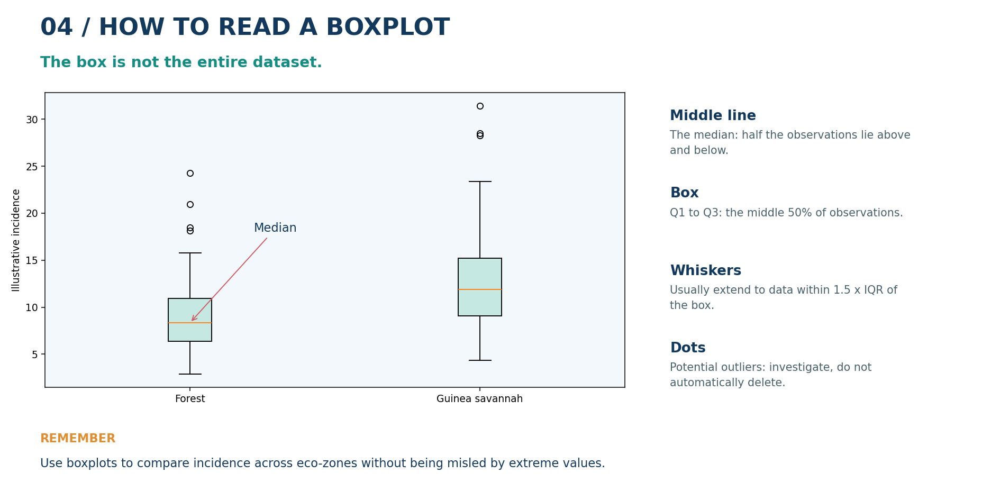
</div>


### Visual explainer: Distributions and log transformations

*This prepares you for the histogram and explains why skewed malaria incidence is often shown on a log scale.*

<div style="text-align:center; margin: 14px 0 26px 0;">
  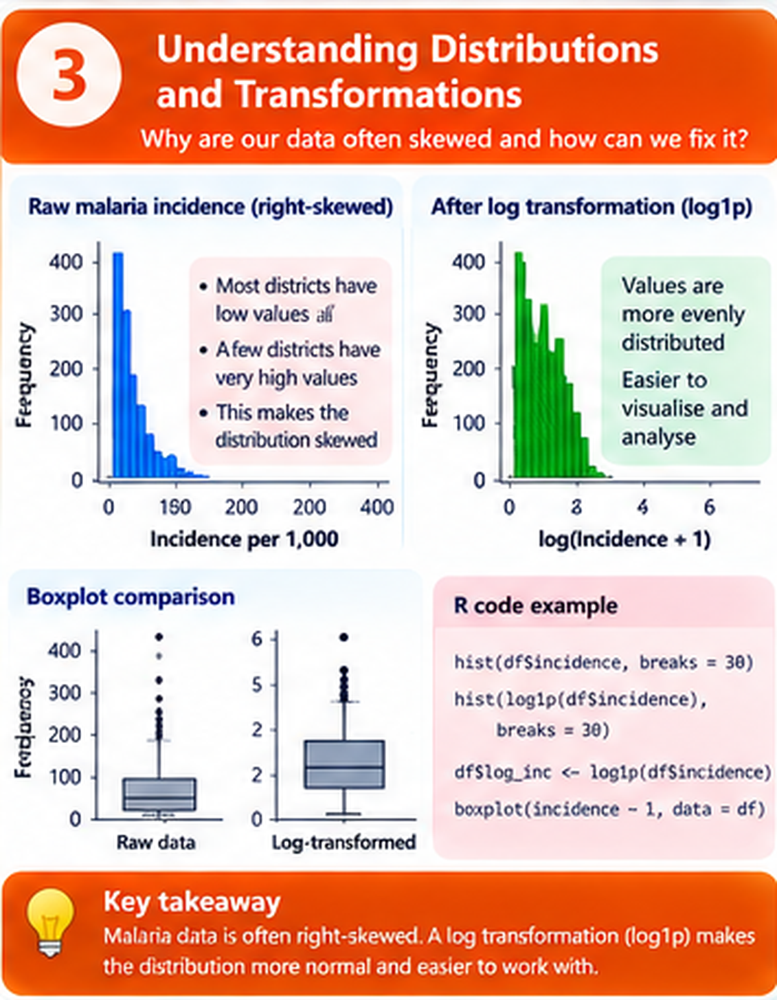
</div>


In [ ]:
a <- panel |> filter(reported) |> ggplot(aes(incidence_1000)) + geom_histogram(bins = 50, fill = "#010066") +
  labs(title = "All reported district-months", x = "incidence per 1,000", y = "district-months") + theme_minimal()
b <- panel |> filter(reported) |> ggplot(aes(incidence_1000)) + geom_histogram(bins = 50, fill = "#C9A063") + scale_x_log10() +
  labs(title = "Same values, log scale", x = "incidence per 1,000 (log scale)", y = NULL) + theme_minimal()
c <- panel |> filter(reported) |> ggplot(aes(eco_zone, incidence_1000, fill = eco_zone)) + geom_boxplot(outlier.size = 0.4, show.legend = FALSE) +
  scale_y_log10() + labs(title = "By ecological zone", x = NULL, y = "incidence per 1,000 (log)") + theme_minimal() +
  theme(axis.text.x = element_text(angle = 20, hjust = 1))
(a + b) / c

Step 4. The national time series and the seasonal profile of each zone.

### Visual explainer: Seasonality and outbreak awareness

*This explains recurring seasonal patterns and how they differ from a possible outbreak signal.*

<div style="text-align:center; margin: 14px 0 26px 0;">
  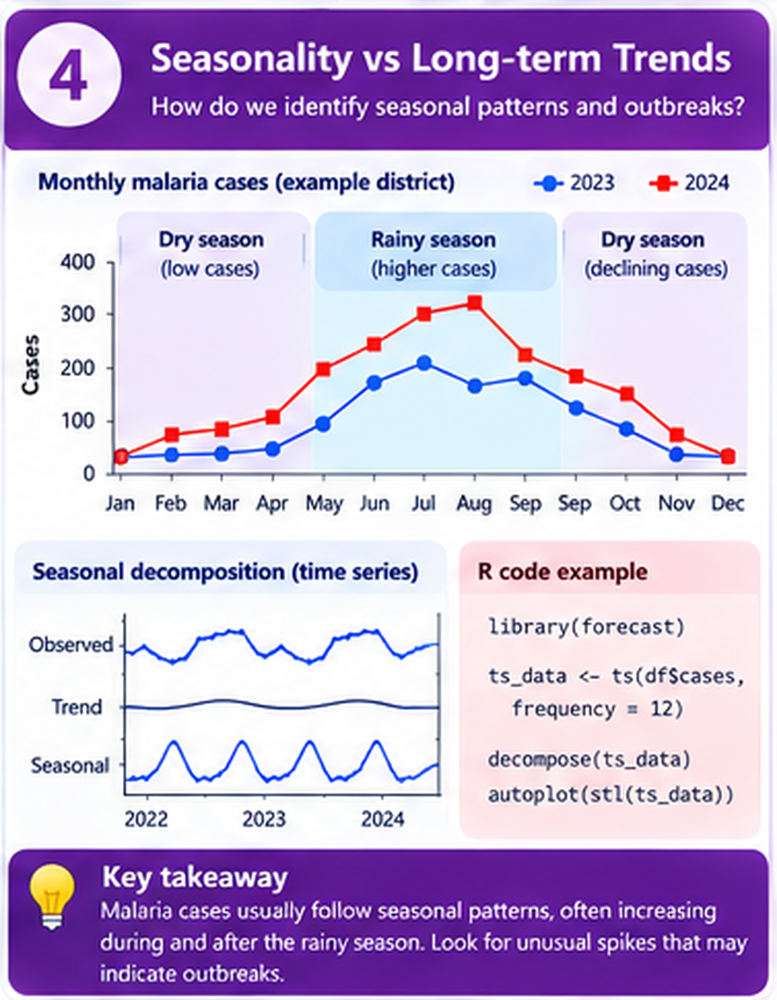
</div>


In [ ]:
national <- panel |> filter(reported) |> group_by(month) |> summarise(confirmed = sum(confirmed), districts = n())
national |> print(n = 24)
seasonal <- panel |> filter(reported) |> group_by(eco_zone, month_of_year) |> summarise(incidence = mean(incidence_1000), .groups = "drop") |>
  group_by(eco_zone) |> mutate(index = incidence / mean(incidence)) |> ungroup()
seasonal |> filter(month_of_year %in% c(1, 4, 8, 11)) |> pivot_wider(id_cols = eco_zone, names_from = month_of_year, values_from = index, names_prefix = "m") |> mutate(across(-eco_zone, ~ round(.x, 2)))

Nationally, confirmed cases rise from about 110,000 in February to about 320,000 in September 2023 and 380,000 in August 2024. The seasonal index table shows the four zones side by side: in the Guinea savannah August is 2.23 times an average month and January 0.41; in the forest and coastal zones the swing is small (0.72 to 1.08). The north has a short, sharp season; the south has malaria all year.

In [ ]:
a <- national |> ggplot(aes(month, confirmed)) + geom_line(colour = "#010066", linewidth = 1) + geom_point(colour = "#010066") +
  scale_y_continuous(labels = comma) + labs(title = "National confirmed cases by month (reported districts only)", x = NULL, y = "confirmed") + theme_minimal()
b <- seasonal |> ggplot(aes(month_of_year, index, colour = eco_zone)) + geom_hline(yintercept = 1, colour = "grey60") + geom_line(linewidth = 1) +
  scale_x_continuous(breaks = 1:12, labels = month.abb) +
  labs(title = "Seasonal profile by ecological zone (month mean / annual mean)", x = NULL, y = "seasonal index", colour = NULL) +
  theme_minimal() + theme(legend.position = "bottom")
a / b

## 1.8 Trial test 1

Answer the trial test on paper (manual section 1.8). Answers are at the end of the manual.

# Topic 2 – Space-Time Visualisation

## 2.4 Step by step in R with Ama's data

Step 1. Annual incidence per district from the usable months, and the 2024 map.

### Visual explainer: Space-time maps and heatmaps

*This helps you interpret annual maps, monthly small multiples and district heatmaps together.*

<div style="text-align:center; margin: 14px 0 26px 0;">
  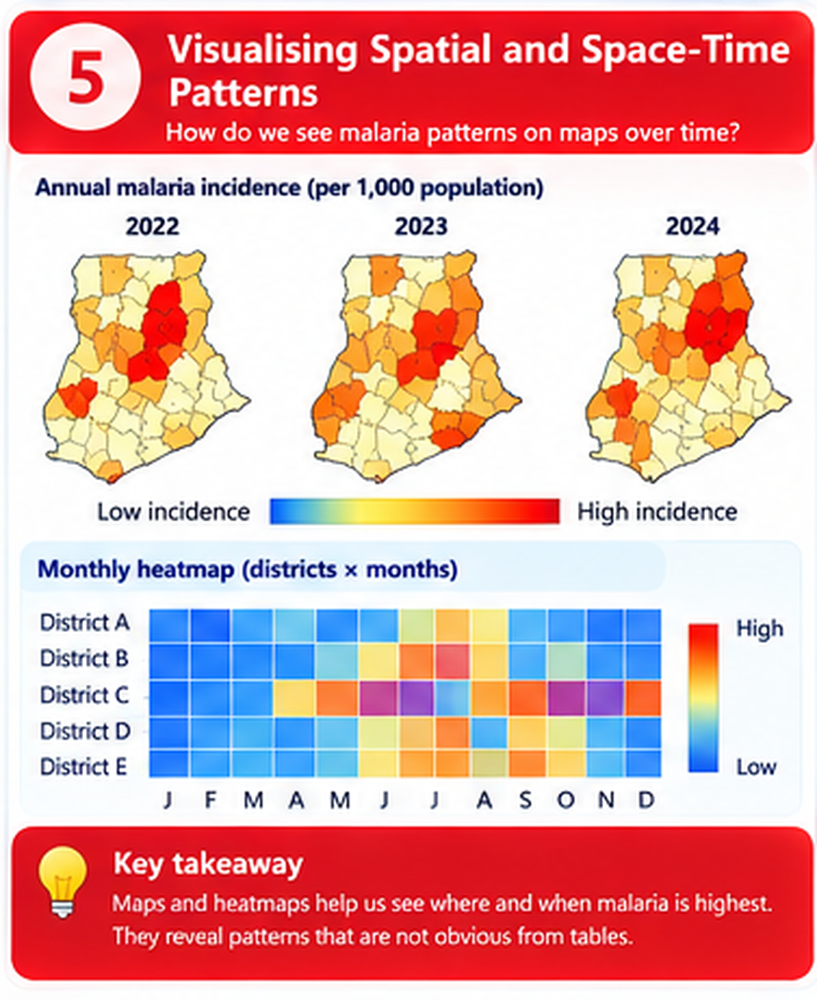
</div>


In [ ]:
annual <- panel |> filter(reported, !flag_outlier) |> group_by(adm2_code, year) |> summarise(incidence = sum(confirmed) / first(population) * 1000, .groups = "drop")
map24  <- districts |> left_join(annual |> filter(year == 2024), by = "adm2_code")
summary(map24$incidence)

In [ ]:
ggplot(map24) + geom_sf(aes(fill = incidence), colour = "white", linewidth = 0.1) +
  scale_fill_viridis_c("per 1,000", option = "inferno", direction = -1) +
  labs(title = "Annual confirmed malaria incidence, 2024", subtitle = "sum of usable months / population x 1,000") + theme_minimal()

Step 2. Twelve monthly maps of 2024 on one capped scale.

In [ ]:
months_2024 <- panel |> filter(year == 2024) |> mutate(inc = if_else(reported & !flag_outlier, incidence_1000, NA_real_))
maps_2024   <- districts |> select(adm2_code) |> left_join(months_2024 |> select(adm2_code, month, inc), by = "adm2_code")
range(maps_2024$inc, na.rm = TRUE)
# the same colour scale on every panel, capped at the 98th percentile so one district does not flatten the rest
cap <- quantile(maps_2024$inc, 0.98, na.rm = TRUE); round(cap, 1)

Monthly incidence runs from 0.7 to 71.7 per 1,000; the cap at the 98th percentile is 36, so the handful of values above 36 are drawn as 36 and the other 98 percent of district-months keep a usable range of colours.

In [ ]:
maps_2024 |> mutate(inc_c = pmin(inc, cap), mon = factor(format(month, "%b"), levels = month.abb)) |>
  ggplot() + geom_sf(aes(fill = inc_c), colour = NA) + facet_wrap(~ mon, ncol = 4) +
  scale_fill_viridis_c("per 1,000", option = "inferno", direction = -1, na.value = "grey85") +
  labs(title = "Monthly incidence per 1,000, 2024 (same scale on every panel; grey = not reported)") +
  theme_void() + theme(strip.text = element_text(face = "bold"))

Step 3. One region district by district: the Upper East heatmap.

In [ ]:
ue <- panel |> filter(region == "Upper East") |> mutate(inc = if_else(reported & !flag_outlier, incidence_1000, NA_real_))
ue_order <- ue |> group_by(adm2_name) |> summarise(m = mean(inc, na.rm = TRUE)) |> arrange(m) |> pull(adm2_name)
ue |> group_by(adm2_name) |> summarise(mean = round(mean(inc, na.rm = TRUE), 1), peak_month = month_of_year[which.max(inc)]) |> arrange(-mean) |> head(5)

In [ ]:
ue |> mutate(adm2_name = factor(adm2_name, levels = ue_order)) |>
  ggplot(aes(month, adm2_name, fill = inc)) + geom_tile(colour = "white") +
  scale_fill_viridis_c("per 1,000", option = "inferno", direction = -1, na.value = "grey85") +
  labs(title = "Upper East: incidence by district and month (districts ordered by mean)", x = NULL, y = NULL) + theme_minimal()

Step 4. What changed between 2023 and 2024.

In [ ]:
change <- annual |> pivot_wider(names_from = year, values_from = incidence, names_prefix = "y") |>
  mutate(ratio = y2024 / y2023, log_ratio = log2(ratio))
change |> summarise(median_ratio = median(ratio, na.rm = TRUE), up_50 = sum(ratio > 1.5, na.rm = TRUE), down_33 = sum(ratio < 0.67, na.rm = TRUE))
change |> left_join(districts |> st_drop_geometry(), by = "adm2_code") |> arrange(-ratio) |> select(adm2_name, region, y2023, y2024, ratio) |> head(5)

The median district was 11 percent higher in 2024. Eight districts rose by more than half, led by West Mamprusi and Bolga East (both 1.76 times), and one fell by more than a third. Bongo does not appear because its flagged August 2024 value was excluded; had it been included it would have shown a spurious 2.85.

Step 5. Rainfall and incidence on one map, for the August 2024 peak.

In [ ]:
# a two-variable map for one peak month: rainfall last month (rain_lag1) and incidence, each cut into low / mid / high thirds
aug <- panel |> filter(month == ymd("2024-08-01"), reported & !flag_outlier) |>
  mutate(rain_cls = ntile(rain_lag1, 3), inc_cls = ntile(incidence_1000, 3),
         bi_class = paste0(rain_cls, "-", inc_cls))
aug |> count(rain_cls, inc_cls) |> pivot_wider(names_from = inc_cls, values_from = n, names_prefix = "inc")

Of the 76 districts in the top rainfall third, 49 are also in the top incidence third and only 13 in the bottom third; of the 77 in the bottom rainfall third, 34 are in the bottom incidence third. The association is there, and the off-diagonal cells (high rain, low incidence; low rain, high incidence) are the districts to ask about.

In [ ]:
a <- districts |> left_join(change, by = "adm2_code") |> ggplot() + geom_sf(aes(fill = log_ratio), colour = "white", linewidth = 0.1) +
  scale_fill_gradient2("log2(2024 / 2023)", low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 0, limits = c(-1.5, 1.5), oob = squish) +
  labs(title = "Change in annual incidence, 2024 vs 2023", subtitle = "red: higher in 2024; blue: lower") + theme_minimal()
bi_cols <- c("1-1" = "#e8e8e8", "2-1" = "#b5c0da", "3-1" = "#6c83b5", "1-2" = "#b8d6be", "2-2" = "#90b2b3", "3-2" = "#567994",
             "1-3" = "#73ae80", "2-3" = "#5a9178", "3-3" = "#2a5a5b")
b <- districts |> left_join(aug |> select(adm2_code, bi_class), by = "adm2_code") |> ggplot() + geom_sf(aes(fill = bi_class), colour = "white", linewidth = 0.1) +
  scale_fill_manual(values = bi_cols, na.value = "grey90", name = "rain_lag1 - incidence\n(1 low, 3 high)") +
  labs(title = "August 2024: rainfall last month and incidence together", subtitle = "dark green: high rain and high incidence; blue: high rain, low incidence") + theme_minimal()
a + b

## 2.8 Trial test 2

Answer the trial test on paper (manual section 2.8). Answers are at the end of the manual.

# Topic 3 – Exploring Relationships Between Predictors and Incidence

### Visual explainer: Rainfall lags and correlation

*This introduces lag 0, lag 1 and lag 2 before you compute ecological-zone correlations.*

<div style="text-align:center; margin: 14px 0 26px 0;">
  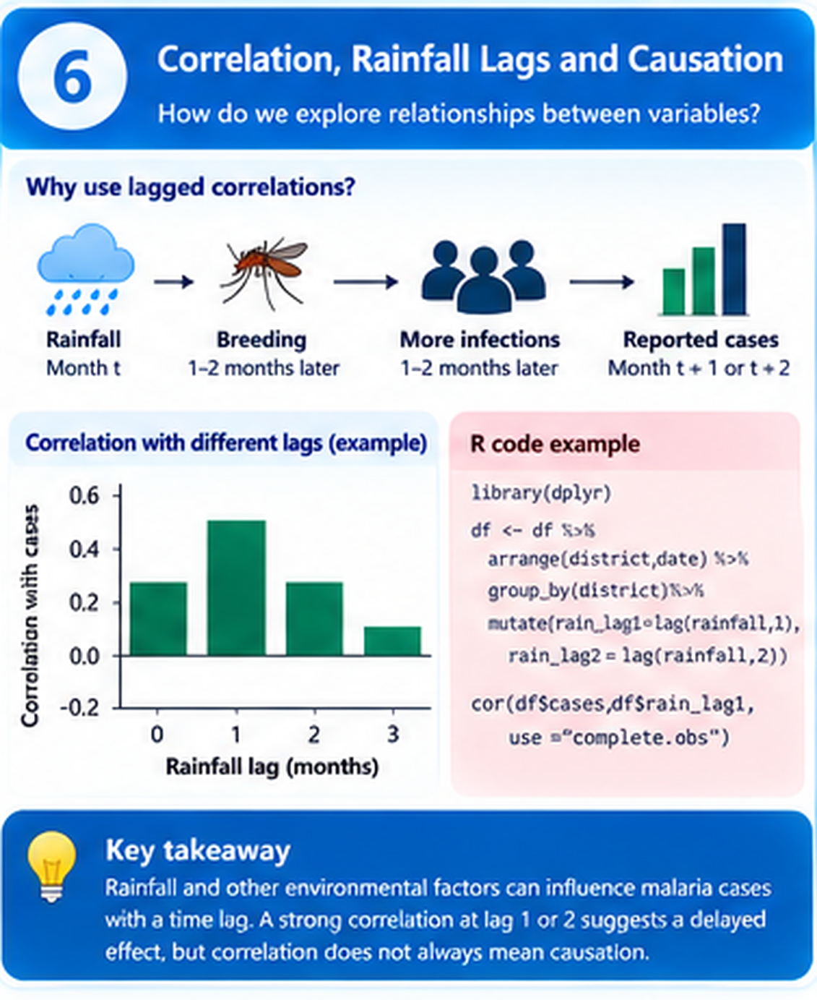
</div>


## 3.4 Step by step in R with Ama's data

Step 1. Correlation of every candidate predictor with incidence, on usable district-months with a two-month history.

In [ ]:
m <- panel |> filter(reported, !flag_outlier, !is.na(rain_lag2))
cor_tbl <- m |> summarise(across(c(rain_mm, rain_lag1, rain_lag2, tmean_c, tmean_lag1, ndvi, elev_m, pop_density, fac_per_10k, cases_lag1),
                                 ~ cor(.x, incidence_1000, use = "complete.obs"))) |> pivot_longer(everything(), names_to = "predictor", values_to = "r") |> mutate(r = round(r, 2)) |> arrange(-abs(r))
cor_tbl

Last month's cases lead (0.44), then rainfall this month and last month (0.37 each), NDVI (-0.36, negative because the savannah is both less green and higher in malaria), elevation (0.25, the north is higher ground), temperature (-0.21) and rainfall two months back (0.20). Population density and facility coverage are weak at this level.

In [ ]:
m |> select(incidence_1000, rain_mm, rain_lag1, rain_lag2, tmean_c) |> pivot_longer(-incidence_1000, names_to = "predictor") |>
  ggplot(aes(value, incidence_1000)) + geom_point(alpha = 0.08, size = 0.5, colour = "#010066") +
  geom_smooth(method = "loess", colour = "#C9A063", se = FALSE) + scale_y_log10() + facet_wrap(~ predictor, scales = "free_x") +
  labs(title = "Incidence against climate predictors (each point is a district-month)", y = "incidence per 1,000 (log)", x = NULL) + theme_minimal()

Step 2. The correlation matrix, and a close look at the climate block.

In [ ]:
preds <- m |> select(incidence_1000, rain_mm, rain_lag1, rain_lag2, tmean_c, tmean_lag1, ndvi, elev_m, pop_density, fac_per_10k)
cm <- cor(preds)
round(cm[c("rain_mm", "rain_lag1", "rain_lag2", "tmean_c", "tmean_lag1"), c("rain_mm", "rain_lag1", "rain_lag2", "tmean_c", "tmean_lag1")], 2)

Rainfall this month and last month are correlated at 0.73; last month and two months back at 0.74. Rainfall two months back and this month's temperature are correlated at -0.75, because the rainy season is cool. A model given all five climate columns will not be able to separate them.

In [ ]:
corrplot(cm, method = "color", type = "upper", addCoef.col = "black", number.cex = 0.7, tl.col = "black", tl.srt = 45,
         col = colorRampPalette(c("#2166AC", "white", "#B2182B"))(200), mar = c(0, 0, 1, 0),
         title = "Correlation matrix: outcome and candidate predictors")

Step 3. The rainfall lag by ecological zone.

In [ ]:
lagcor <- m |> group_by(eco_zone) |> summarise(lag0 = cor(rain_mm, incidence_1000), lag1 = cor(rain_lag1, incidence_1000), lag2 = cor(rain_lag2, incidence_1000)) |>
  mutate(across(-eco_zone, ~ round(.x, 2)))
lagcor

In [ ]:
lagcor |> pivot_longer(-eco_zone, names_to = "lag", values_to = "r") |>
  ggplot(aes(lag, r, fill = eco_zone)) + geom_col(position = "dodge") +
  labs(title = "Rainfall-incidence correlation at lags 0 to 2, by ecological zone", x = "rainfall lag", y = "correlation", fill = NULL) +
  theme_minimal() + theme(legend.position = "bottom")

Step 4. Last month's cases, and the simple non-spatial reference model.

In [ ]:
# the strongest single predictor is last month's cases: check it, then check what it leaves unexplained
m |> summarise(r_cases_lag1 = cor(cases_lag1, confirmed, use = "complete.obs"), r_inc_lag1 = cor(cases_lag1 / population * 1000, incidence_1000, use = "complete.obs"))
# a simple non-spatial reference model on the training months (Module 5 will do this properly)
train <- m |> filter(split == "train")
fit0 <- lm(log1p(incidence_1000) ~ rain_lag1 + tmean_c + ndvi + log(pop_density) + fac_per_10k + season, data = train)
round(summary(fit0)$r.squared, 2)
round(coef(fit0), 4)

Last month's cases and this month's cases are correlated at 0.93; on the incidence scale, 0.69. The reference model (rainfall last month, temperature, NDVI, log density, facility coverage and season, on the training months) explains 27 percent of the variation in log incidence. Every coefficient has the expected sign: more rain, less NDVI (savannah), fewer people per square kilometre and the wet season all go with higher incidence. Module 5 will do much better; the point here is the 73 percent that this model does not explain, which Topic 4 examines.

In [ ]:
sd_ <- m |> group_by(adm2_code, eco_zone) |>
  summarise(incidence = mean(incidence_1000), elev_m = first(elev_m), ndvi = first(ndvi),
            log10_pop_density = log10(first(pop_density)), fac_per_10k = first(fac_per_10k), .groups = "drop")
sd_ |> pivot_longer(c(elev_m, ndvi, log10_pop_density, fac_per_10k), names_to = "predictor") |>
  ggplot(aes(value, incidence, colour = eco_zone)) + geom_point(alpha = 0.7, size = 1.2) + scale_y_log10() + facet_wrap(~ predictor, scales = "free_x") +
  labs(title = "District mean incidence against static predictors (one point per district)", y = "mean incidence per 1,000 (log)", x = NULL, colour = NULL) +
  theme_minimal() + theme(legend.position = "bottom")

## 3.8 Trial test 3

Answer the trial test on paper (manual section 3.8). Answers are at the end of the manual.

# Topic 4 – Spatial Structure Over Time

## 4.4 Step by step in R with Ama's data

Step 1. Build the weights as in Module 1, then Moran's I for every month.

### Visual explainer: Spatial clustering through time

*This connects Moran’s I over time to changing geographic clustering patterns.*

<div style="text-align:center; margin: 14px 0 26px 0;">
  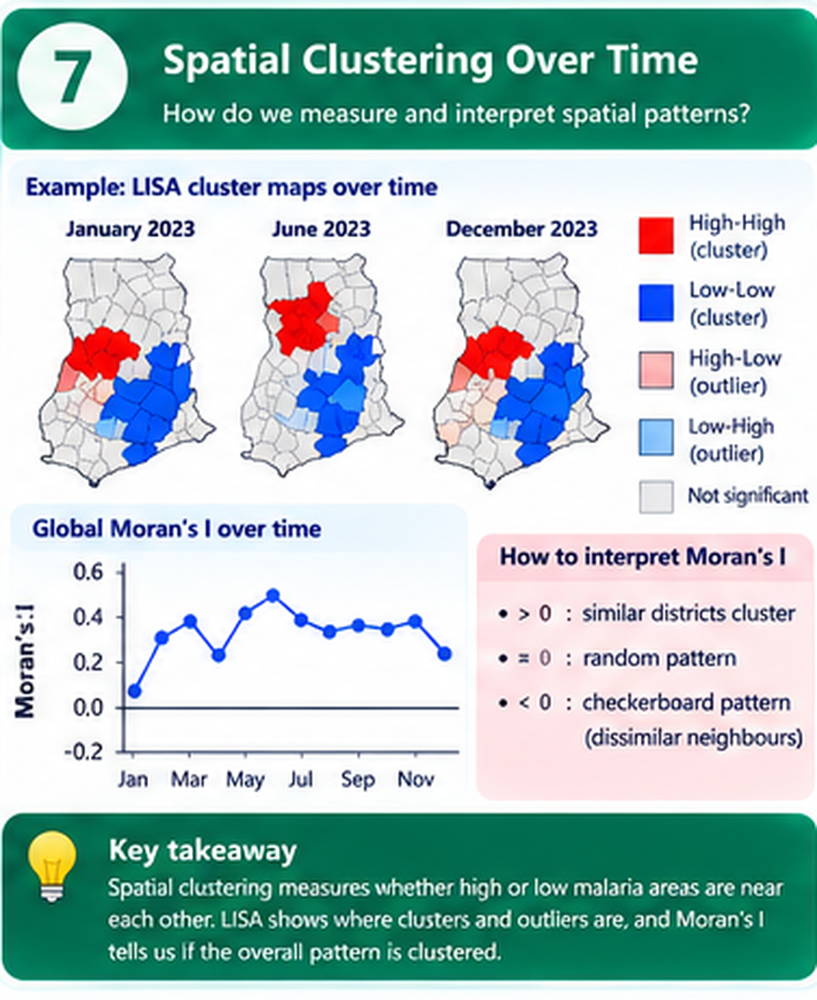
</div>


In [ ]:
nb_q <- poly2nb(districts, queen = TRUE)          # exactly as in Module 1 Topic 2
lw_q <- nb2listw(nb_q, style = "W", zero.policy = TRUE)
moran_month <- function(mo) {
  x <- panel |> filter(month == mo) |> mutate(inc = if_else(reported & !flag_outlier, incidence_1000, NA_real_)) |> arrange(match(adm2_code, districts$adm2_code))
  x$inc[is.na(x$inc)] <- median(x$inc, na.rm = TRUE)     # fill gaps with the median so the weights stay aligned
  mt <- moran.test(x$inc, lw_q, zero.policy = TRUE)
  tibble(month = mo, I = unname(mt$estimate[1]), p = mt$p.value)
}
mi <- map_dfr(unique(panel$month), moran_month) |> mutate(I = round(I, 3))
mi |> print(n = 24)
mi |> summarise(min = min(I), max = max(I), all_significant = all(p < 0.001))

Moran's I is 0.03 in January 2023 and not significant (p = 0.17); it climbs to 0.66 in August 2023, falls back to near zero in the 2024 dry season and climbs again to 0.71 in August 2024. The clustering that Module 1 found in annual incidence is almost entirely a wet-season phenomenon: in the dry months the map is close to random.

In [ ]:
mi |> ggplot(aes(month, I)) + geom_line(colour = "#010066", linewidth = 1) + geom_point(aes(colour = p < 0.001), size = 2.5) +
  scale_colour_manual("p < 0.001", values = c("TRUE" = "#010066", "FALSE" = "red")) +
  labs(title = "Global Moran I of monthly incidence, 2023-2024", subtitle = "queen contiguity weights, as in Module 1", x = NULL, y = "Moran I") +
  theme_minimal() + theme(legend.position = "bottom")

Step 2. LISA for every month, and the persistence of High-High and Low-Low clusters.

In [ ]:
lisa_month <- function(mo) {
  x <- panel |> filter(month == mo) |> mutate(inc = if_else(reported & !flag_outlier, incidence_1000, NA_real_)) |> arrange(match(adm2_code, districts$adm2_code))
  x$inc[is.na(x$inc)] <- median(x$inc, na.rm = TRUE)
  lm_ <- localmoran(x$inc, lw_q, zero.policy = TRUE)
  z  <- as.numeric(scale(x$inc)); lag <- lag.listw(lw_q, z)
  tibble(adm2_code = x$adm2_code, month = mo,
         hh = z > 0 & lag > 0 & lm_[, 5] < 0.05, ll = z < 0 & lag < 0 & lm_[, 5] < 0.05)
}
lisa_all <- map_dfr(unique(panel$month), lisa_month)
persist <- lisa_all |> group_by(adm2_code) |> summarise(months_hh = sum(hh), months_ll = sum(ll)) |>
  mutate(type = case_when(months_hh >= 12 ~ "Persistent high cluster", months_hh >= 4 ~ "Seasonal high cluster",
                          months_ll >= 12 ~ "Persistent low cluster", months_ll >= 4 ~ "Seasonal low cluster", TRUE ~ "No stable cluster"))
persist |> count(type)
persist |> left_join(districts |> st_drop_geometry(), by = "adm2_code") |> arrange(-months_hh) |> select(adm2_name, region, months_hh) |> head(8)

Twelve districts are significant High-High clusters in at least 12 of the 24 months, all in the Upper East and North East regions, with Nabdam at 18 months; 31 more are seasonal; only one district is a persistent Low-Low cluster, and 209 districts never form a stable cluster of either kind.

In [ ]:
districts |> left_join(persist, by = "adm2_code") |> ggplot() + geom_sf(aes(fill = type), colour = "white", linewidth = 0.1) +
  scale_fill_manual(values = c("Persistent high cluster" = "#B2182B", "Seasonal high cluster" = "#EF8A62", "Persistent low cluster" = "#2166AC",
                               "Seasonal low cluster" = "#67A9CF", "No stable cluster" = "grey88"), name = NULL) +
  labs(title = "LISA cluster persistence over 24 months", subtitle = "persistent: significant in 12+ of 24 months\nseasonal: significant in 4 to 11 months") +
  theme_minimal() + theme(legend.position = "bottom") + guides(fill = guide_legend(nrow = 2))

Step 3. Are the reference model's residuals spatially clustered?

In [ ]:
# residuals of the non-spatial reference model, averaged per district, then tested for spatial autocorrelation
train$resid <- residuals(fit0)
res_d <- train |> group_by(adm2_code) |> summarise(mean_resid = mean(resid))
res_map <- districts |> select(adm2_code, adm2_name, region) |> left_join(res_d, by = "adm2_code")
res_map$mean_resid[is.na(res_map$mean_resid)] <- 0
moran.test(res_map$mean_resid, lw_q, zero.policy = TRUE)$estimate[1] |> round(3)
moran.mc(res_map$mean_resid, lw_q, nsim = 999, zero.policy = TRUE)$p.value
res_map |> st_drop_geometry() |> arrange(-mean_resid) |> head(5)

Moran's I of the district mean residuals is 0.072 with a Monte Carlo p-value of 0.027: small but real. The districts with the largest positive residuals (the model under-predicts them by about 0.67 on the log scale, that is by about a factor of two) are scattered across Eastern, Ashanti, Western and Central regions, not the north. The plain model has absorbed the north through NDVI and elevation but misses pockets in the south.

In [ ]:
ggplot(res_map) + geom_sf(aes(fill = mean_resid), colour = "white", linewidth = 0.1) +
  scale_fill_gradient2("mean residual\n(log scale)", low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 0) +
  labs(title = "What the reference model leaves unexplained", subtitle = "district mean residual; red: more incidence than predicted, blue: less") + theme_minimal()

## 4.8 Trial test 4

Answer the trial test on paper (manual section 4.8). Answers are at the end of the manual.

# Topic 5 – Interactive Maps and the Esda Brief

## 5.4 Step by step in R with Ama's data

Step 1. Prepare one table for the map: WGS84, simplified, with every popup column joined.

### Visual explainer: Interactive maps and reporting

*This shows how ESDA findings become a communication product for decision-makers.*

<div style="text-align:center; margin: 14px 0 26px 0;">
  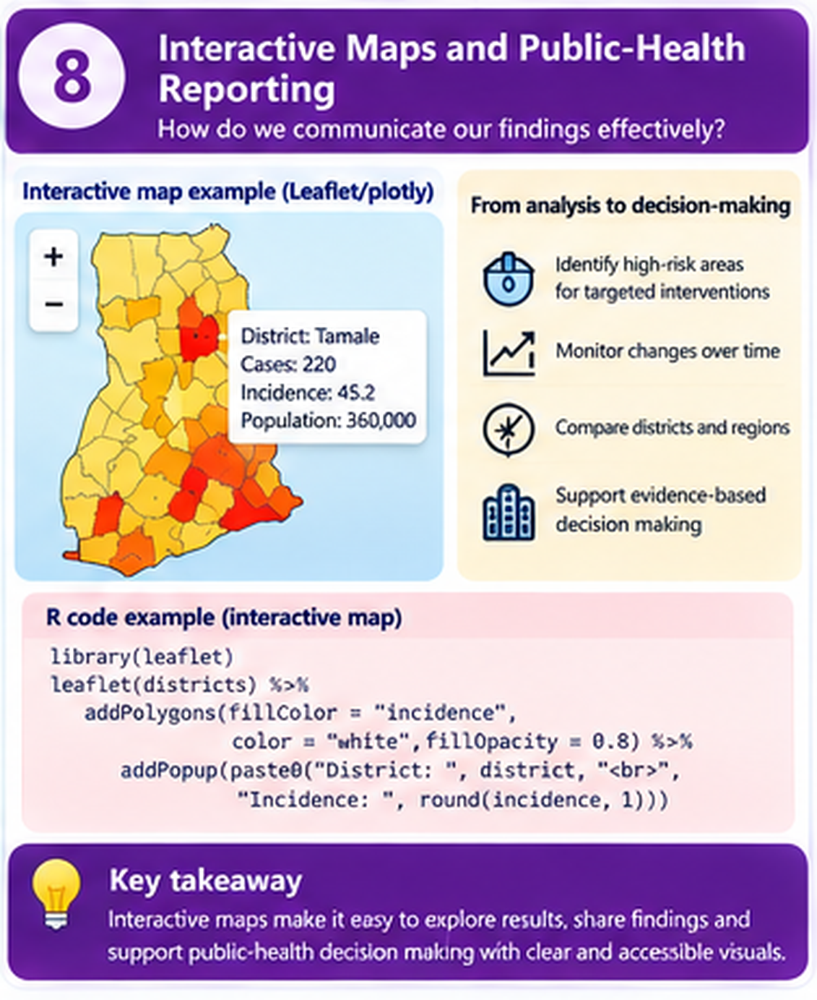
</div>


In [ ]:
# one layer to share: 2024 annual incidence, with what a reader needs in the popup
web <- districts |> st_transform(4326) |>
  left_join(annual |> filter(year == 2024) |> select(adm2_code, inc_2024 = incidence), by = "adm2_code") |>
  left_join(persist |> select(adm2_code, type, months_hh), by = "adm2_code") |>
  left_join(panel |> filter(year == 2024, reported) |> group_by(adm2_code) |> summarise(cases_2024 = sum(confirmed), months_reported = n(), population = first(population)), by = "adm2_code") |>
  st_simplify(dTolerance = 200)            # smaller file: web maps do not need every vertex
object.size(districts) |> format(units = "MB"); object.size(web) |> format(units = "MB")
web |> st_drop_geometry() |> select(adm2_name, inc_2024, cases_2024, months_reported, type) |> head(4)

From 10.3 MB to 0.7 MB. The four printed rows show what the popup will carry; note Asutifi North with 8 months reported, which its popup will say.

Step 2. The first interactive map: one layer, a fixed-break palette, popups, hover labels and a legend.

In [ ]:
library(leaflet)
pal <- colorBin("YlOrRd", domain = web$inc_2024, bins = c(0, 50, 100, 150, 200, 300, 500, 1000))
popup <- paste0("<b>", web$adm2_name, "</b> (", web$region, ")<br>",
                "2024 incidence: ", round(web$inc_2024, 1), " per 1,000<br>",
                "Confirmed cases: ", format(web$cases_2024, big.mark = ","), "<br>",
                "Months reported: ", web$months_reported, " of 12<br>",
                "Cluster status: ", web$type)
m1 <- leaflet(web) |>
  addProviderTiles(providers$CartoDB.Positron) |>
  addPolygons(fillColor = ~pal(inc_2024), fillOpacity = 0.75, color = "white", weight = 0.7,
              popup = popup, label = ~adm2_name,
              highlightOptions = highlightOptions(weight = 2, color = "#010066", bringToFront = TRUE)) |>
  addLegend(pal = pal, values = ~inc_2024, title = "2024 incidence<br>per 1,000", position = "bottomright")
m1

In Colab the map appears under the cell when the object m1 is printed. If it does not, run it again as the last line of the cell, or go straight to Step 4 and open the saved file.

Step 3. Two layers and a layer control.

In [ ]:
pal_type <- colorFactor(c("#B2182B", "#EF8A62", "#2166AC", "#67A9CF", "grey85"),
                        levels = c("Persistent high cluster", "Seasonal high cluster", "Persistent low cluster", "Seasonal low cluster", "No stable cluster"))
m2 <- leaflet(web) |>
  addProviderTiles(providers$CartoDB.Positron) |>
  addPolygons(fillColor = ~pal(inc_2024), fillOpacity = 0.75, color = "white", weight = 0.7, popup = popup, group = "Incidence 2024") |>
  addPolygons(fillColor = ~pal_type(type), fillOpacity = 0.75, color = "white", weight = 0.7, popup = popup, group = "Cluster persistence") |>
  addLegend(pal = pal, values = ~inc_2024, title = "Incidence per 1,000", group = "Incidence 2024", position = "bottomright") |>
  addLegend(pal = pal_type, values = ~type, title = "LISA cluster, 2023-24", group = "Cluster persistence", position = "bottomleft") |>
  addLayersControl(baseGroups = c("Incidence 2024", "Cluster persistence"), options = layersControlOptions(collapsed = FALSE))
m2

Step 4. Save the map as one HTML file and check its size, then download it from the Files panel.

In [ ]:
htmlwidgets::saveWidget(m2, file.path(out_dir, "malaria_2024_interactive.html"), selfcontained = TRUE)
round(file.size(file.path(out_dir, "malaria_2024_interactive.html")) / 1e6, 1)     # MB; download from the Files panel

The file is about 1.5 MB with the simplified boundaries and the two layers. It opens in any browser, on a phone included, and can be attached to an email or placed on a shared drive. Without the simplification in Step 1 it would be over 20 MB.

### Step 5. The ESDA brief

The last product is a page of text. Ama's, built from the checkpoint numbers of this module, is in the next section. The structure is fixed: the panel and the usable rows; the outcome and its transformation; the season and the zones; the predictors, their strength, lags and collinearity; the spatial structure and its seasonality; the residual test; the exclusions and the settings. Each paragraph names a figure or a number from Topics 1 to 4.

## 5.8 Trial test 5

Answer the trial test on paper (manual section 5.8). Answers are at the end of the manual.

---
End of the module. Download anything you want to keep from the Files panel before the session ends.

## Export for the web map viewer

Added by `tools/prepare_notebooks.py`: writes the map layers listed in `layers.json`.

In [ ]:
# ---- Export for the web map viewer (added by tools/prepare_notebooks.py) ----
# Each block below is wrapped in safe(): if a step was edited or skipped, the other layers are
# still written. The viewer discovers everything through layers.json.
layers <- list()
safe <- function(label, expr) tryCatch(expr, error = function(e)
  message("Export skipped - ", label, ": ", conditionMessage(e)))
add_layer <- function(...) layers[[length(layers) + 1]] <<- list(...)
wgs <- function(x) sf::st_transform(x, 4326)

# district polygons, in lon/lat, lightly simplified for the web
web_districts <- function(d, tol = 0.002) {
  d <- wgs(d)
  keep <- intersect(c("adm2_code", "adm2_name", "region", "eco_zone"), names(d))
  suppressWarnings(sf::st_simplify(d[, keep], preserveTopology = TRUE, dTolerance = tol))
}
write_geojson <- function(x, name) {
  f <- file.path(out_dir, paste0(name, ".geojson"))
  if (file.exists(f)) file.remove(f)
  x <- dplyr::mutate(x, dplyr::across(dplyr::where(is.numeric), ~ round(.x, 4)))
  sf::st_write(x, f, driver = "GeoJSON", quiet = TRUE, layer_options = "COORDINATE_PRECISION=5")
}
# long district-month table -> one column per month (inc_2024_01, ...) + field list for the slider
widen_months <- function(df, value, prefix) {
  df <- as.data.frame(df)
  d  <- data.frame(adm2_code = df$adm2_code, key = paste0(prefix, "_", format(df$month, "%Y_%m")), v = df[[value]])
  m  <- sort(unique(df$month))
  list(wide   = tidyr::pivot_wider(d, names_from = "key", values_from = "v"),
       fields = lapply(m, function(x) list(field = paste0(prefix, "_", format(x, "%Y_%m")), label = format(x, "%b %Y"))))
}
# x/y/value data frame -> heat-point JSON for the browser + a GeoTIFF for GIS users
heat_export <- function(df, name, crs = 32630, max_pts = 25000) {
  df <- df[is.finite(df$value), c("x", "y", "value")]
  tryCatch(terra::writeRaster(terra::rast(df, type = "xyz", crs = paste0("EPSG:", crs)),
                              file.path(out_dir, paste0(name, ".tif")), overwrite = TRUE),
           error = function(e) message("GeoTIFF skipped for ", name, ": ", conditionMessage(e)))
  if (nrow(df) > max_pts) df <- df[round(seq(1, nrow(df), length.out = max_pts)), ]
  ll <- sf::st_coordinates(wgs(sf::st_as_sf(df, coords = c("x", "y"), crs = crs)))
  jsonlite::write_json(list(points = data.frame(lat = ll[, 2], lng = ll[, 1], value = df$value)),
                       file.path(out_dir, paste0(name, ".heat.json")), digits = 6)
}
im_df  <- function(im) { d <- as.data.frame(im); names(d)[3] <- "value"; d }          # spatstat image
pts_df <- function(s, col) { xy <- sf::st_coordinates(s); data.frame(x = xy[, 1], y = xy[, 2], value = s[[col]]) }

# ESDA: annual incidence, cluster persistence, change, residuals, bivariate map, 24-month series
safe("esda map", {
  mo  <- widen_months(dplyr::mutate(panel, inc = dplyr::if_else(reported & !flag_outlier, incidence_1000, NA_real_)), "inc", "inc")
  att <- sf::st_drop_geometry(web) |> dplyr::select(adm2_code, inc_2024, cases_2024, months_reported, population, type, months_hh)
  d <- web_districts(districts) |>
    dplyr::left_join(att, by = "adm2_code") |>
    dplyr::left_join(dplyr::select(change, adm2_code, y2023, y2024, ratio, log_ratio), by = "adm2_code") |>
    dplyr::left_join(sf::st_drop_geometry(res_map) |> dplyr::select(adm2_code, mean_resid), by = "adm2_code") |>
    dplyr::left_join(dplyr::select(aug, adm2_code, bi_class), by = "adm2_code") |>
    dplyr::left_join(mo$wide, by = "adm2_code")
  write_geojson(d, "esda_districts")
  persist_cols <- list("Persistent high cluster" = "#B2182B", "Seasonal high cluster" = "#EF8A62", "Persistent low cluster" = "#2166AC",
                       "Seasonal low cluster" = "#67A9CF", "No stable cluster" = "#E0E0E0")
  add_layer(id = "esda", title = "ESDA: incidence, clusters, change", kind = "choropleth", file = "esda_districts.geojson",
    fields = list(
      list(field = "inc_2024",  label = "Annual incidence 2024 (per 1,000)", type = "numeric"),
      list(field = "type",      label = "LISA cluster persistence, 2023-24", type = "category", colors = persist_cols),
      list(field = "log_ratio", label = "Change 2024 vs 2023 (log2 ratio)", type = "numeric"),
      list(field = "mean_resid", label = "Unexplained by reference model (mean residual)", type = "numeric"),
      list(field = "months_hh", label = "Months in a high-high cluster", type = "numeric"),
      list(field = "bi_class",  label = "Aug 2024: rain last month x incidence (1 low, 3 high)", type = "category")))
  add_layer(id = "monthly", title = "Monthly incidence per 1,000, 2023-24", kind = "choropleth", file = "esda_districts.geojson",
    series = list(list(id = "inc", label = "Usable months only", fields = mo$fields))) })
safe("moran table", readr::write_csv(mi, file.path(out_dir, "moran_monthly.csv")))

jsonlite::write_json(list(layers = layers), file.path(out_dir, "layers.json"),
                     auto_unbox = TRUE, null = "null", na = "null")
cat("Exported", length(layers), "map layer(s) to", out_dir, "\n")
print(list.files(out_dir))
